# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
432,0.009016,-0.044642,0.055229,-0.005670,0.057597,0.044719,-0.002903,0.023239,0.055686,0.106617,173.0
94,-0.078165,-0.044642,-0.016984,-0.012556,-0.000193,-0.013527,0.070730,-0.039493,-0.041176,-0.092204,90.0
32,0.034443,0.050680,0.125287,0.028758,-0.053855,-0.012900,-0.102307,0.108111,0.000272,0.027917,341.0
370,0.019913,-0.044642,-0.057941,-0.057313,-0.001569,-0.012587,0.074412,-0.039493,-0.061176,-0.075636,63.0
77,-0.096328,-0.044642,-0.036385,-0.074527,-0.038720,-0.027618,0.015505,-0.039493,-0.074093,-0.001078,200.0
441,-0.045472,-0.044642,-0.073030,-0.081413,0.083740,0.027809,0.173816,-0.039493,-0.004222,0.003064,57.0
302,0.012648,-0.044642,0.033673,0.033337,0.030078,0.027183,-0.002903,0.008847,0.031193,0.027917,198.0
38,-0.001882,0.050680,0.071397,0.097615,0.087868,0.075407,-0.021311,0.071210,0.071429,0.023775,252.0
253,0.081666,-0.044642,0.033673,0.008101,0.052093,0.056619,-0.017629,0.034309,0.034866,0.069338,150.0
159,-0.005515,-0.044642,0.043373,0.087287,0.013567,0.007141,-0.013948,-0.002592,0.042341,-0.017646,195.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [7]:
# Crear una copia de los datos originales
data_simple = data.copy()

# Crear el imputador utilizando la media
imputer = SimpleImputer(strategy='mean')

# Sustituir los valores faltantes de bmi
data_simple[['bmi']] = imputer.fit_transform(data_simple[['bmi']])
data_simple['bmi'].isnull().sum()

np.int64(0)

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [8]:
# Crear una copia de los datos originales
data_knn = data.copy()

# Crear el imputador KNN
knn_imputer = KNNImputer(n_neighbors=5)

# Imputar las columnas bmi y bp
data_knn[['bmi', 'bp']] = knn_imputer.fit_transform(data_knn[['bmi', 'bp']])

In [9]:
data_knn[['bmi', 'bp']].isnull().sum()

bmi    0
bp     0
dtype: int64

In [10]:
print("Media original de bmi:", data['bmi'].mean())
print("Media con imputación simple:", data_simple['bmi'].mean())
print("Media con KNN:", data_knn['bmi'].mean())

Media original de bmi: -0.00020486982495318998
Media con imputación simple: -0.00020486982495319117
Media con KNN: 0.00021273180711015857


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

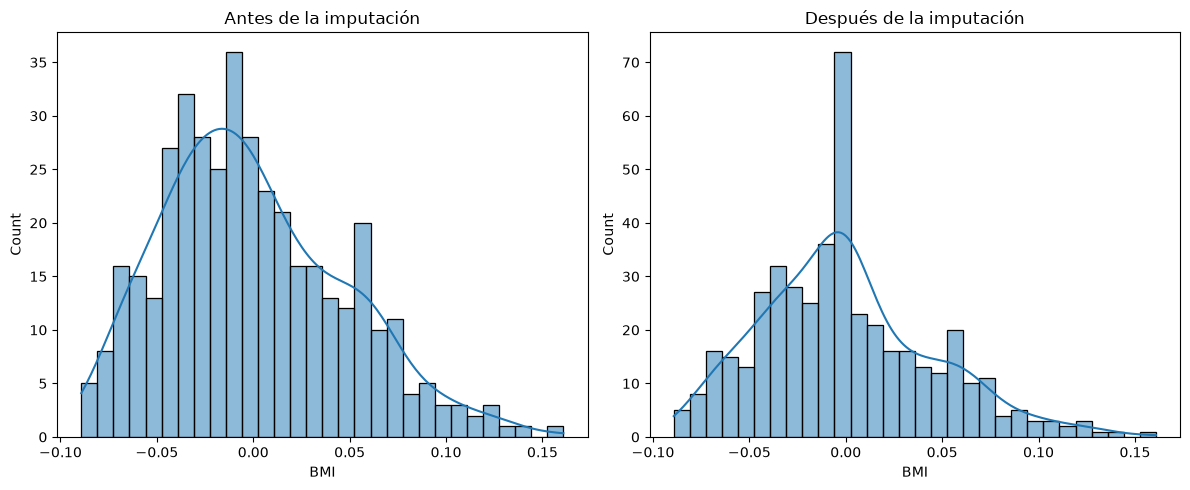

In [11]:
# Crear una figura con dos histogramas
plt.figure(figsize=(12, 5))

# Histograma antes de la imputación
plt.subplot(1, 2, 1)
sns.histplot(data['bmi'], bins=30, kde=True)
plt.title('Antes de la imputación')
plt.xlabel('BMI')

# Histograma después de la imputación
plt.subplot(1, 2, 2)
sns.histplot(data_simple['bmi'], bins=30, kde=True)
plt.title('Después de la imputación')
plt.xlabel('BMI')

# Mostrar gráficas
plt.tight_layout()
plt.show()